# Function 4 - Week 5: Cohort Model Predictions

#### Model Predictions using Official Observations up to and including Week 4 return, received on **23 October 2026**. Retained cohort snapshot: **20 October 2026**.

In [1]:
# Imports and shared helpers.
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display

shared_dir = next(
    (folder / "Shared" for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Shared" / "model_review_helpers.py").is_file()), None,
)
if shared_dir is None:
    raise FileNotFoundError("Run from this notebook's folder inside notebooks/.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))

from exploration_review_helpers import load_exploration_review
from model_review_helpers import (
    make_regression_models, fit_model_review, review_latest_predictions,
    build_review_candidates, score_review_candidates,
    query_prediction, weight_sensitivity,
)
from model_review_plots import plot_held_out_comparison, plot_latest_predictions
from coverage_cache import compare_coverage_batches
from query_budget import remaining_queries
from plot_helpers import PLOT_CONFIG
from model_review_plots import plot_coordinate_model_review
from cohort_review_helpers import (
    load_cohort_review, paired_target_comparison, read_saved_proposal,
    common_candidate_comparison, compare_proposal_predictions,
)
from model_review_plots import plot_paired_cohort_profiles

In [2]:
# Settings for this run. Keep model assumptions and search settings here.
FUNCTION_NUMBER = 4
CURRENT_WEEK = 5
INPUT_COLUMNS = ["x1", "x2", "x3", "x4"]
OUTPUT_COLUMN = "y"
EXPECTED_ROUND_COUNTS = {0: 30, 1: 1, 2: 1, 3: 1, 4: 1}
ANALYSIS_DIR = Path.cwd().resolve()
WEEK_DIR = ANALYSIS_DIR.parent
DATA_PATH = ANALYSIS_DIR / "observations.csv"
FIGURES_DIR = ANALYSIS_DIR / "figures"
TITLE = f"Function {FUNCTION_NUMBER} - Week {CURRENT_WEEK} cohort"
PORTAL_DECIMALS = 6
MODEL_NAMES = ["Mean baseline", "Linear regression", "Ridge", "Kernel ridge", "Gaussian process"]
GP_NAMES = ["Gaussian process"]
# Retain the existing GP diagonal regularisation; it is not a measured noise level.
MODEL_SETTINGS = dict(
    noise_fraction=0.10, ridge_alpha=1.0,
    kernel_ridge_alpha=0.1, kernel_ridge_gamma=1.0,
    length_scale=0.3, length_scale_bounds=(0.03, 2.0),
    amplitude=1.0, amplitude_bounds=(0.01, 100.0), optimiser_restarts=3, seed=42,
)
EXPLORATION_WEIGHT = 1.96
SEARCH_SETTINGS = dict(
    broad_power=14, broad_seed=42, local_power=12, local_seed=43,
    local_radius=0.15, precision=PORTAL_DECIMALS, include_corners=True,
)
COVERAGE_SETTINGS = dict(
    max_queries=1, optimization_power=12, evaluation_power=15,
    optimization_seed=42, evaluation_seed=43, comparison_seed=42, verbose=False,
)
EXPLORATION_WEIGHTS = (0.0, 1.0, 1.96, 3.0)
VALIDATION_MODELS = ["Ridge", "Kernel ridge"]
COORDINATE_VIEW_SETTINGS = dict(side=250, padding_fraction=0.05, figsize=(16, 4.6))
CANDIDATES_TO_SHOW = 5
VALIDATION_SIZE = (15, 5)
LATEST_RESULT_SIZE = (11, 5.5)
OFFICIAL_DIR = WEEK_DIR / "official"
OFFICIAL_DATA_PATH = OFFICIAL_DIR / "observations.csv"
OFFICIAL_MODEL_PATH = OFFICIAL_DIR / "model_predictions.ipynb"
EXPECTED_PEER_COUNT = 6
PEER_ROUND_MAX = 2
COHORT_COMPARISON_SIZE = (14, 5.5)

In [3]:
# Validate the same snapshot used by the exploration review.
review = load_cohort_review(
    DATA_PATH, OFFICIAL_DATA_PATH, input_columns=INPUT_COLUMNS, output_column=OUTPUT_COLUMN,
    expected_round_counts=EXPECTED_ROUND_COUNTS,
    expected_peer_count=EXPECTED_PEER_COUNT, peer_round_max=PEER_ROUND_MAX,
)
inputs = review["inputs"].to_numpy(dtype=float)
raw_y = review["outputs"].to_numpy(dtype=float)
anchor = inputs[int(np.argmax(raw_y))].copy()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
display(review["latest_submissions"].drop(columns="comparison"))

,observation_id,source_round,x1,x2,x3,x4,y,output_rank
33,round-04,4,0.354513,0.376712,0.37896,0.488593,-1.25916,5


In [4]:
# Fit each complete estimator within every held-out fold.
models = make_regression_models(len(INPUT_COLUMNS), **MODEL_SETTINGS)
models = {name: models[name] for name in MODEL_NAMES}
model_run = fit_model_review(models, inputs, raw_y, gp_names=GP_NAMES)
selected_model = model_run["selected_model"]
modelled_axes = tuple(range(len(INPUT_COLUMNS)))
display(model_run["table"].round(6))
display(pd.Series({"Selected GP": model_run["selected_name"], "Fitted kernel": model_run["fitted_kernel"]}))

,Model,Training MAE,LOO MAE,LOO RMSE,MAE / baseline,RMSE reduction (%)
0,Gaussian process,0.239646,1.076257,1.488783,0.139988,84.457118
1,Kernel ridge,1.734335,2.957067,3.867669,0.384625,59.621562
2,Ridge,5.748182,6.337827,7.337392,0.824359,23.397679
3,Linear regression,5.597750,6.393896,7.474964,0.831652,21.961425
4,Mean baseline,7.495985,7.688189,9.578550,1.000000,0.000000


Selected GP                       Gaussian process
Fitted kernel    1.51**2 * RBF(length_scale=0.672)
dtype: str

,Model,Latest held-out prediction,Latest error,Latest absolute error (%),Latest share of squared error (%),Other rows LOO RMSE
0,Gaussian process,-0.7861,0.4730,37.5678,0.2524,1.5058
1,Kernel ridge,-4.2279,-2.9687,235.7678,1.4729,3.8880
2,Linear regression,-11.7722,-10.5131,834.9262,4.9452,7.3806
3,Ridge,-12.1861,-10.9270,867.7992,5.5444,7.2219
4,Mean baseline,-14.5048,-13.2456,1051.9397,4.7806,9.4659


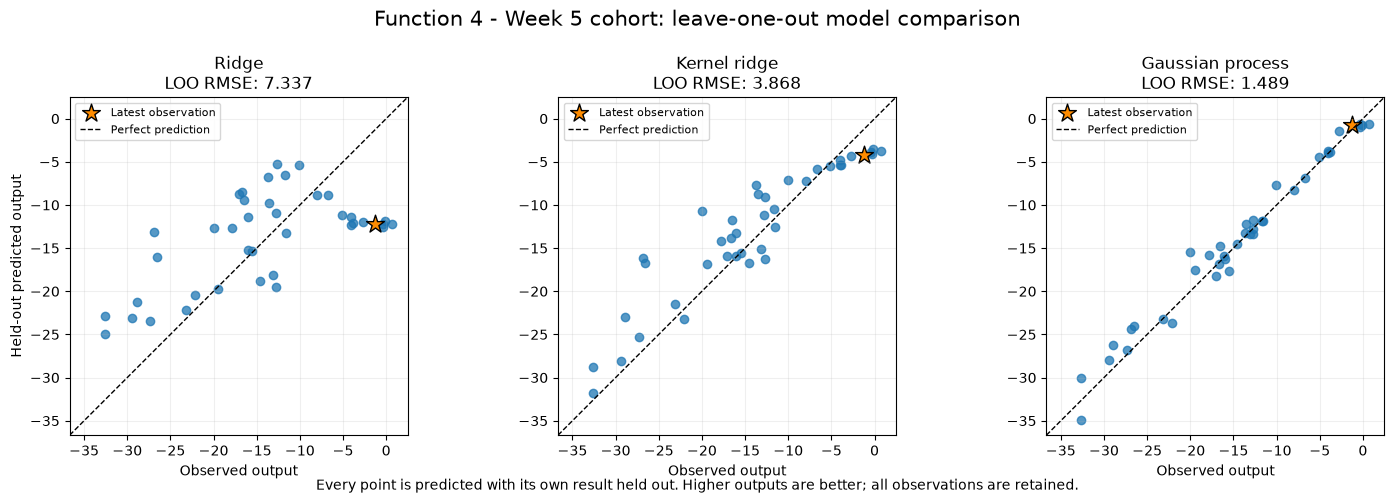

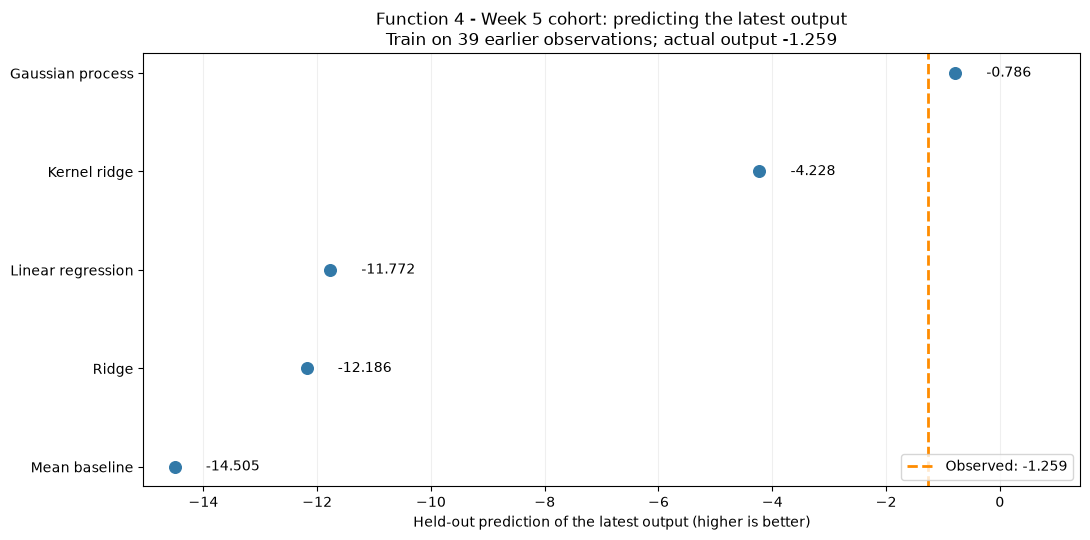

In [5]:
# This checks the latest held-out result retrospectively; it is not a saved forecast.
latest_review = review_latest_predictions(model_run["predictions"], raw_y, review["latest_mask"])
latest_output = float(raw_y[review["latest_mask"]][0])
display(latest_review.round(4))
display(plot_held_out_comparison(
    model_run["predictions"], raw_y,
    model_names=[*VALIDATION_MODELS, model_run["selected_name"]], latest_mask=review["latest_mask"],
    title=f"{TITLE}: leave-one-out model comparison", figsize=VALIDATION_SIZE,
    save_to=FIGURES_DIR / "model-comparison-validation.png",
))
display(plot_latest_predictions(
    latest_review, latest_output, n_training_rows=int((~review["latest_mask"]).sum()),
    title=f"{TITLE}: predicting the latest output", figsize=LATEST_RESULT_SIZE,
    save_to=FIGURES_DIR / "latest-output-predictions.png",
))

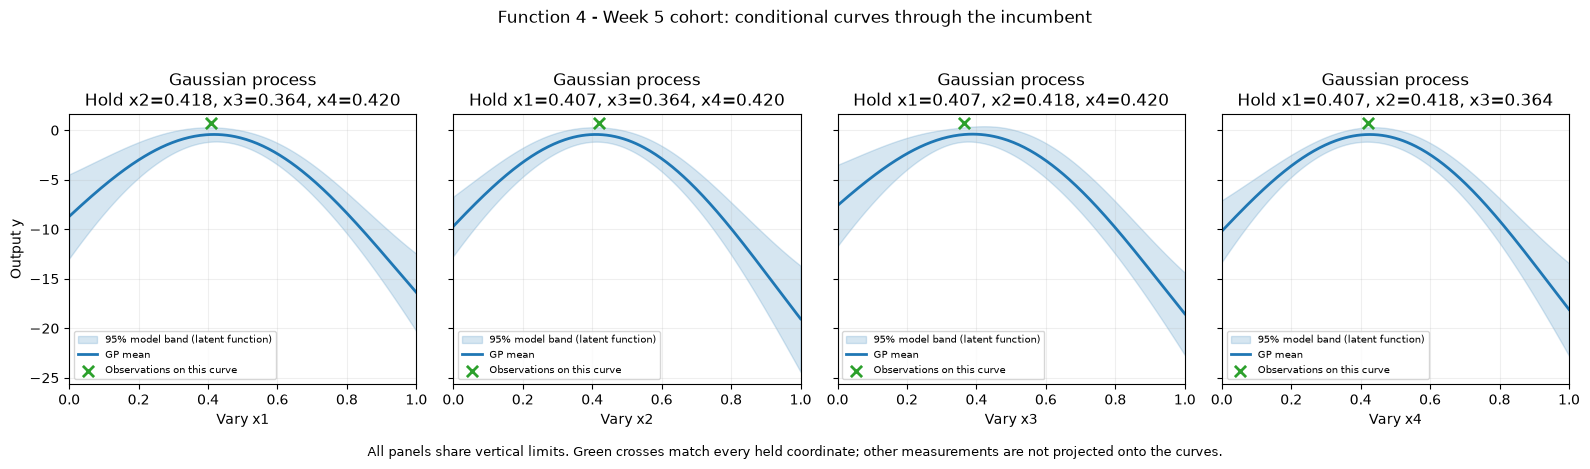

In [6]:
# Vary one coordinate at a time through the measured incumbent, holding all others fixed.
plot_coordinate_model_review(
    {name: model_run["fitted"][name] for name in GP_NAMES}, inputs, raw_y, anchor,
    input_columns=INPUT_COLUMNS, title=f"{TITLE}: conditional curves through the incumbent",
    **COORDINATE_VIEW_SETTINGS, save_to=FIGURES_DIR / "gp-coordinate-slices.png",
)

In [7]:
# Reuse the geometric coverage cache, then score the exact rounded candidate inputs.
coverage = compare_coverage_batches(
    existing=inputs, cache_dir=ANALYSIS_DIR / ".coverage-cache", **COVERAGE_SETTINGS,
)
candidates = build_review_candidates(
    inputs, anchor, coverage["proposed_batches"][1], input_columns=INPUT_COLUMNS, **SEARCH_SETTINGS,
)
scored = score_review_candidates(
    selected_model, candidates, input_columns=INPUT_COLUMNS,
    weight=EXPLORATION_WEIGHT, precision=PORTAL_DECIMALS,
)
by_source = scored.loc[scored.groupby("candidate_source")["ucb"].idxmax()].sort_values("ucb", ascending=False)
display(by_source.round(6))
display(pd.DataFrame(coverage["results"]))

,x1,x2,x3,x4,posterior_mean,posterior_sd,ucb,candidate_source
0,0.372337,0.419841,0.442391,0.452843,-0.708365,0.571328,0.411437,Near incumbent
31,0.445683,0.395023,0.413569,0.454466,-0.552766,0.426763,0.283689,Full input space
13821,0.791460,0.031242,0.706787,0.678378,-20.527646,3.400440,-13.862783,Single coverage query


,q,max_distance,p95_distance
0,0,0.663919,0.445774
1,1,0.663919,0.435792


In [8]:
# Every coordinate remains free in the rounded candidate comparison.
recommended = scored.iloc[0]
next_query = recommended[INPUT_COLUMNS].to_numpy(dtype=float)
proposal = query_prediction(
    selected_model, next_query, inputs, raw_y, weight=EXPLORATION_WEIGHT, precision=PORTAL_DECIMALS,
)
proposal_source = recommended.candidate_source
display(pd.Series(proposal))

point                         [0.372337, 0.419841, 0.442391, 0.452843]
predicted_output                                             -0.708365
posterior_std                                                 0.571328
ucb                                                           0.411437
predicted_mean_improvement                                   -1.420511
inside_sampled_hull                                               True
portal_input                       0.372337-0.419841-0.442391-0.452843
dtype: object

In [9]:
# Reuse the same candidate pool and predictions while changing the exploration weight.
exploration_sensitivity = weight_sensitivity(
    scored, inputs, input_columns=INPUT_COLUMNS, modelled_axes=modelled_axes,
    weights=EXPLORATION_WEIGHTS, precision=PORTAL_DECIMALS,
)
display(exploration_sensitivity.round(6))

,Weight,x1,x2,x3,x4,Predicted output,Posterior SD
0,0.00,0.403269,0.411754,0.400096,0.434522,-0.407497,0.417431
1,1.00,0.403269,0.411754,0.400096,0.434522,-0.407497,0.417431
2,1.96,0.372337,0.419841,0.442391,0.452843,-0.708365,0.571328
3,3.00,0.347925,0.433063,0.469088,0.444488,-1.054285,0.697999


In [10]:
# Retain every coordinate in the alternatives; these predictions are not measured outputs.
display(scored.head(CANDIDATES_TO_SHOW)[[
    *INPUT_COLUMNS, "posterior_mean", "posterior_sd", "ucb", "candidate_source",
]].round(PORTAL_DECIMALS))

,x1,x2,x3,x4,posterior_mean,posterior_sd,ucb,candidate_source
0,0.372337,0.419841,0.442391,0.452843,-0.708365,0.571328,0.411437,Near incumbent
1,0.403269,0.411754,0.400096,0.434522,-0.407497,0.417431,0.410668,Near incumbent
2,0.374617,0.391278,0.428728,0.428172,-0.593869,0.509068,0.403904,Near incumbent
3,0.419096,0.406060,0.408855,0.426466,-0.413201,0.409220,0.388869,Near incumbent
4,0.380284,0.444077,0.420229,0.421047,-0.589390,0.496334,0.383424,Near incumbent


In [11]:
# Keep this exploratory summary separate from the saved official proposal.
analysis_summary = {
    "function": FUNCTION_NUMBER, "week": CURRENT_WEEK, "observations": len(raw_y),
    "query_model": model_run["selected_name"], "analysis_scope": "cohort_snapshot_comparison",
    "proposal_status": "exploratory_not_submitted",
    "portal_input": proposal["portal_input"], "point": proposal["point"],
    "predicted_output": proposal["predicted_output"], "posterior_std": proposal["posterior_std"],
    "ucb_weight": EXPLORATION_WEIGHT, "candidate_source": proposal_source,
    "candidate_count": len(scored),
    "inside_sampled_hull": proposal["inside_sampled_hull"], "best_observed_output": float(raw_y.max()),
    "gp_rmse": model_run["selected_rmse"], "baseline_rmse": model_run["baseline_rmse"],
    "gp_baseline_rmse_ratio": model_run["selected_rmse"] / model_run["baseline_rmse"],
    "lowest_rmse_model": model_run["table"].iloc[0]["Model"],
    "distinct_weight_choices": len(exploration_sensitivity[INPUT_COLUMNS].drop_duplicates()),
    "remaining_queries": remaining_queries(WEEK_DIR),
    "own_observations": int(review["own_mask"].sum()), "peer_observations": int(review["peer_mask"].sum()),
    "model_comparison": model_run["table"].to_dict(orient="records"),
    "fitted_kernel": model_run["fitted_kernel"],
    "length_scales": np.atleast_1d(selected_model.kernel_.k2.length_scale).tolist(),
    "weight_sensitivity": exploration_sensitivity.to_dict(orient="records"),
}
print(json.dumps(analysis_summary, indent=2))

{
  "function": 4,
  "week": 5,
  "observations": 40,
  "query_model": "Gaussian process",
  "analysis_scope": "cohort_snapshot_comparison",
  "proposal_status": "exploratory_not_submitted",
  "portal_input": "0.372337-0.419841-0.442391-0.452843",
  "point": [
    0.372337,
    0.419841,
    0.442391,
    0.452843
  ],
  "predicted_output": -0.7083652857024845,
  "posterior_std": 0.5713276735102845,
  "ucb_weight": 1.96,
  "candidate_source": "Near incumbent",
  "candidate_count": 20513,
  "inside_sampled_hull": true,
  "best_observed_output": 0.7121459305130498,
  "gp_rmse": 1.4887827020788225,
  "baseline_rmse": 9.578549823854345,
  "gp_baseline_rmse_ratio": 0.15542882058943513,
  "lowest_rmse_model": "Gaussian process",
  "distinct_weight_choices": 3,
  "remaining_queries": 9,
  "own_observations": 34,
  "peer_observations": 6,
  "model_comparison": [
    {
      "Model": "Gaussian process",
      "Training MAE": 0.23964586464674512,
      "LOO MAE": 1.0762571957833886,
      "LOO R

In [12]:
# Score identical official targets, aligning the pooled held-out predictions by ID.
own_inputs = review["own_data"][INPUT_COLUMNS].to_numpy(dtype=float)
own_y = review["own_data"][OUTPUT_COLUMN].to_numpy(dtype=float)
own_run = fit_model_review(models, own_inputs, own_y, gp_names=GP_NAMES)
paired_comparison = paired_target_comparison(
    own_run, model_run, own_y, own_positions=review["own_positions"],
    peer_count=int(review["peer_mask"].sum()),
)
own_summary = read_saved_proposal(
    OFFICIAL_MODEL_PATH, function=FUNCTION_NUMBER, week=CURRENT_WEEK,
    model_run=own_run, observation_count=len(own_y),
)
own_next = np.asarray(own_summary["point"], dtype=float)
display(paired_comparison.round(6))

,Model,Own-target RMSE: 33 training rows,Own-target RMSE: 33 own + 6 peer training rows,Own-target MAE: own training,Own-target MAE: pooled training
0,Mean baseline,8.654269,8.698072,6.737888,6.733208
1,Linear regression,6.979268,7.282012,5.878846,6.125889
2,Ridge,6.856622,6.906622,5.641139,5.857911
3,Kernel ridge,4.444830,4.066917,3.532399,3.144093
4,Gaussian process,1.466791,1.543057,0.988323,1.122493


In [13]:
# Freeze one candidate union for both fits, then predict at both actual proposals.
own_coverage = compare_coverage_batches(
    existing=own_inputs, cache_dir=OFFICIAL_DIR / ".coverage-cache", **COVERAGE_SETTINGS,
)
comparison_fits = {
    f"Official {len(own_y)}-row fit": own_run,
    f"Pooled {len(raw_y)}-row fit": model_run,
}
common_comparison = common_candidate_comparison(
    comparison_fits,
    [candidates[INPUT_COLUMNS].to_numpy(), own_coverage["proposed_batches"][1], own_next, next_query],
    inputs, input_columns=INPUT_COLUMNS, weight=EXPLORATION_WEIGHT, precision=PORTAL_DECIMALS,
)
proposal_comparison = compare_proposal_predictions(
    comparison_fits,
    {"Official provisional point": own_next, "Cohort exploratory point": next_query},
    input_columns=INPUT_COLUMNS, weight=EXPLORATION_WEIGHT,
)
display(common_comparison.round(6))
display(proposal_comparison.round(6))
plot_paired_cohort_profiles(
    paired_comparison, {"Official proposal": own_next, "Cohort alternative": next_query},
    input_columns=INPUT_COLUMNS, target_count=len(own_y),
    title=f"Function {FUNCTION_NUMBER} - Week {CURRENT_WEEK}: adding the retained peer observations",
    figsize=COHORT_COMPARISON_SIZE, save_to=FIGURES_DIR / "official-versus-cohort.png",
)
comparison_summary = {
    "function": FUNCTION_NUMBER, "week": CURRENT_WEEK, "analysis": "official_vs_retained_cohort",
    "official": own_summary, "cohort": analysis_summary,
    "paired_targets": paired_comparison.to_dict(orient="records"),
    "common_candidates": common_comparison.to_dict(orient="records"),
    "proposal_predictions": proposal_comparison.to_dict(orient="records"),
}
print(json.dumps(comparison_summary, indent=2))

,Fit,Model,x1,x2,x3,x4,posterior_mean,posterior_sd,ucb,Candidates
0,Official 34-row fit,Gaussian process,0.419096,0.406060,0.408855,0.426466,-0.689570,0.429507,0.152263,20514
1,Pooled 40-row fit,Gaussian process,0.372337,0.419841,0.442391,0.452843,-0.708365,0.571328,0.411437,20514


,Point,Fit,x1,x2,x3,x4,Mean,SD,UCB
0,Official provisional point,Official 34-row fit,0.414390,0.395070,0.420904,0.438653,-0.756502,0.456939,0.139098
1,Official provisional point,Pooled 40-row fit,0.414390,0.395070,0.420904,0.438653,-0.475331,0.446141,0.399105
2,Cohort exploratory point,Official 34-row fit,0.372337,0.419841,0.442391,0.452843,-1.026177,0.552686,0.057088
3,Cohort exploratory point,Pooled 40-row fit,0.372337,0.419841,0.442391,0.452843,-0.708365,0.571328,0.411437


{
  "function": 4,
  "week": 5,
  "analysis": "official_vs_retained_cohort",
  "official": {
    "function": 4,
    "week": 5,
    "observations": 34,
    "query_model": "Gaussian process",
    "proposal_status": "proposed_not_submitted",
    "portal_input": "0.414390-0.395070-0.420904-0.438653",
    "point": [
      0.41439,
      0.39507,
      0.420904,
      0.438653
    ],
    "predicted_output": -0.756502460682281,
    "posterior_std": 0.4569390594440746,
    "ucb_weight": 1.96,
    "candidate_source": "Near incumbent",
    "candidate_count": 20513,
    "inside_sampled_hull": true,
    "best_observed_output": -0.12991814521724931,
    "gp_rmse": 1.4667906142808187,
    "baseline_rmse": 8.65426864237204,
    "gp_baseline_rmse_ratio": 0.1694875297837747,
    "lowest_rmse_model": "Gaussian process",
    "distinct_weight_choices": 3,
    "remaining_queries": 9,
    "model_comparison": [
      {
        "Model": "Gaussian process",
        "Training MAE": 0.16158929389722795,
        